# Fine-tuning Qwen2.5-1.5B-Instruct for Text-to-SQL (with explanations)

**Task:** given a database schema + a natural-language question, generate a SQLite query **and** a short explanation.
**Data:** [`gretelai/synthetic_text_to_sql`](https://huggingface.co/datasets/gretelai/synthetic_text_to_sql) (prepared by `prepare_data.py`).
**Method:** LoRA fine-tuning of `Qwen/Qwen2.5-1.5B-Instruct`; evaluate the **same** 300 test questions before and after.

**Metrics** (each test schema ships with `INSERT` rows, so we can actually run the SQL in SQLite):
| metric | meaning |
|---|---|
| Execution accuracy | predicted SQL returns the same rows as the gold SQL (row order ignored) |
| Executable rate | predicted SQL runs without error |
| Exact match | normalized SQL string equals gold |
| Format compliance | output has a ```sql block **and** an `Explanation:` |
| Explanation ROUGE-L | overlap of generated vs gold explanation |

**Before running on Colab**
1. Runtime → Change runtime type → **GPU** (L4 or A100 recommended; T4 works but slower).
2. Put `prepare_data.py` in Google Drive at `MyDrive/text-to-sql-finetuning/prepare_data.py` (if it is missing, the data cell will ask you to upload it).

**Folder layout** (shared data outside, each version in its own folder):
```
text-to-sql-finetuning/
├── prepare_data.py        shared
├── data/test.jsonl        shared test set
├── data/v1/  data/v2/     per-version train/val
├── v1/  (this notebook, results/, outputs/)
└── v2/
```
   The notebook regenerates `data/` if missing, and writes adapters / results back to Drive so a disconnect doesn't lose work.

In [1]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "transformers>=4.45", "peft>=0.13", "accelerate", "datasets", "rouge_score"], check=True)
    # Colab's preinstalled torchao is older than new peft accepts ("incompatible version of torchao");
    # we don't use quantization, so remove it.
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


## 1. Config

In [2]:
MODEL_ID   = "Qwen/Qwen2.5-1.5B-Instruct"
PROJECT_DIR = "/content/drive/MyDrive/text-to-sql-finetuning" if IN_COLAB else os.getcwd()

# Smoke test = tiny run to check the pipeline end-to-end (a few minutes). Set False for the real run.
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

N_TRAIN        = None    # None = use all of data/v1/train.jsonl (10k)
N_EVAL         = 300     # test questions for before/after comparison
MAX_LEN        = 1024    # tokens per training example (p99 is ~500)
MAX_NEW_TOKENS = 320     # generation budget (SQL + explanation)
GEN_BATCH      = 16

# LoRA / training hyper-parameters
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
EPOCHS, LR = 1, 2e-4
BATCH, GRAD_ACCUM = 8, 2          # effective batch 16 -> ~625 steps for 10k examples
MAX_STEPS = -1                    # -1 = run full epochs

if SMOKE_TEST:
    MODEL_ID = os.environ.get("SMOKE_MODEL", "Qwen/Qwen2.5-0.5B-Instruct")
    N_TRAIN, N_EVAL, MAX_NEW_TOKENS, GEN_BATCH = 32, 6, 96, 6
    BATCH, GRAD_ACCUM, MAX_STEPS = 2, 1, 4

RUN_NAME    = MODEL_ID.split("/")[-1].lower() + "-text2sql-lora" + ("-smoke" if SMOKE_TEST else "")
VERSION_DIR = os.path.join(PROJECT_DIR, "v1")
DATA_DIR    = os.path.join(PROJECT_DIR, "data", "v1")              # v1 train/val (raw data)
TEST_PATH   = os.path.join(PROJECT_DIR, "data", "test.jsonl")      # shared test set
OUT_DIR     = os.path.join(VERSION_DIR, "outputs", RUN_NAME)       # checkpoints + final adapter
RESULTS_DIR = os.path.join(VERSION_DIR, "results" + ("_smoke" if SMOKE_TEST else ""))
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(RESULTS_DIR, exist_ok=True)
os.chdir(PROJECT_DIR); sys.path.insert(0, PROJECT_DIR)
print(MODEL_ID, "|", PROJECT_DIR, "| smoke test:", SMOKE_TEST)

Qwen/Qwen2.5-1.5B-Instruct | /content/drive/MyDrive/text-to-sql-finetuning | smoke test: False


## 2. Data
Re-uses `prepare_data.py` (same prompt template, same SQLite runner) so training and evaluation stay consistent.

In [3]:
if not os.path.exists(os.path.join(PROJECT_DIR, "prepare_data.py")):
    print(f"prepare_data.py not found in {PROJECT_DIR}. Contents: {os.listdir(PROJECT_DIR)}")
    if not IN_COLAB:
        raise FileNotFoundError("prepare_data.py")
    from google.colab import files
    print("Please upload prepare_data.py:")
    for name, content in files.upload().items():          # saved into PROJECT_DIR (on Drive)
        open(os.path.join(PROJECT_DIR, os.path.basename(name)), "wb").write(content)

if not (os.path.exists(os.path.join(DATA_DIR, "train.jsonl")) and os.path.exists(TEST_PATH)):
    r = subprocess.run([sys.executable, "prepare_data.py", "--out", os.path.join(PROJECT_DIR, "data"), "--name", "v1"],
                       capture_output=True, text=True)
    print(r.stdout[-2000:]); print(r.stderr[-3000:])
    r.check_returncode()

import json
import pandas as pd
from prepare_data import SYSTEM_PROMPT, build_user, run_sql

def read_jsonl(path, n=None):
    rows = [json.loads(l) for l in open(path)]
    return rows[:n] if n else rows

train_rows = read_jsonl(os.path.join(DATA_DIR, "train.jsonl"), N_TRAIN)
val_rows   = read_jsonl(os.path.join(DATA_DIR, "val.jsonl"), 16 if SMOKE_TEST else None)
test_rows  = read_jsonl(TEST_PATH, N_EVAL)
print(f"train={len(train_rows)}  val={len(val_rows)}  test={len(test_rows)}")
print("\n--- example target ---\n" + train_rows[0]["messages"][-1]["content"])

train=10000  val=500  test=300

--- example target ---
```sql
SELECT COUNT(*) FROM Support_Services WHERE Service_Type = 'Tutoring' AND Disability_Type = 'Visual Impairment';
```

Explanation: This SQL query filters the Support_Services table by Service_Type 'Tutoring' and Disability_Type 'Visual Impairment' and then counts the number of students who meet these criteria.


## 3. Load the base model

In [4]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16   # T4 -> fp16
elif torch.backends.mps.is_available():
    DEVICE, DTYPE = "mps", torch.float32
else:
    DEVICE, DTYPE = "cpu", torch.float32
print(DEVICE, DTYPE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.padding_side = "left"          # left-pad for batched generation
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE).to(DEVICE)
print(f"{sum(p.numel() for p in model.parameters())/1e9:.2f}B parameters")

cuda torch.bfloat16 NVIDIA L4


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

1.54B parameters


## 4. Generation + evaluation helpers

In [5]:
import re, time
from collections import Counter
from tqdm.auto import tqdm
from rouge_score import rouge_scorer

def build_prompt(context, question):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": build_user(context, question)}]
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def generate(model, prompts, batch_size=GEN_BATCH, max_new_tokens=MAX_NEW_TOKENS):
    model.eval()
    outs = []
    for i in tqdm(range(0, len(prompts), batch_size), desc="generating"):
        enc = tokenizer(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None,
                             pad_token_id=tokenizer.pad_token_id)
        outs += tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return outs

def extract_sql(text):
    m = re.search(r"```(?:sql|sqlite)?\s*(.*?)```", text, re.S | re.I)
    if m:
        return m.group(1).strip()
    m = re.search(r"\b((?:SELECT|WITH)\b.*?)(?:;|\n\n|$)", text, re.S | re.I)   # fallback: bare query
    return m.group(1).strip() if m else text.strip()

def extract_explanation(text):
    m = re.search(r"Explanation:\s*(.*)", text, re.S | re.I)
    if m:
        return m.group(1).strip()
    return re.sub(r"```.*?```", "", text, flags=re.S).strip()   # whatever prose is outside the code block

def norm_sql(s):
    return re.sub(r"\s+", " ", s.strip().rstrip(";")).lower()

def same_result(a, b):
    # multiset comparison: row order ignored, floats rounded
    norm = lambda rows: Counter(tuple(round(v, 4) if isinstance(v, float) else v for v in r) for r in rows)
    return a is not None and b is not None and norm(a) == norm(b)

_rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def evaluate(model, rows, tag):
    t0 = time.time()
    outputs = generate(model, [build_prompt(r["sql_context"], r["sql_prompt"]) for r in rows])
    secs = time.time() - t0
    recs = []
    for r, out in zip(rows, outputs):
        pred_sql = extract_sql(out)
        gold_res, pred_res = run_sql(r["sql_context"], r["sql"]), run_sql(r["sql_context"], pred_sql)
        recs.append({
            "id": r["id"], "sql_complexity": r["sql_complexity"], "question": r["sql_prompt"],
            "gold_sql": r["sql"], "pred_sql": pred_sql, "raw_output": out,
            "format_ok": bool(re.search(r"```sql", out, re.I)) and "explanation:" in out.lower(),
            "executable": pred_res is not None,
            "exec_match": same_result(gold_res, pred_res),
            "exact_match": norm_sql(pred_sql) == norm_sql(r["sql"]),
            "expl_rougeL": _rouge.score(r["sql_explanation"], extract_explanation(out))["rougeL"].fmeasure,
        })
    df = pd.DataFrame(recs)
    df.to_json(os.path.join(RESULTS_DIR, f"{tag}_predictions.jsonl"), orient="records", lines=True, force_ascii=False)
    summary = {"model": tag, "n": len(df), "exec_accuracy": df.exec_match.mean(), "executable_rate": df.executable.mean(),
               "exact_match": df.exact_match.mean(), "format_compliance": df.format_ok.mean(),
               "explanation_rougeL": df.expl_rougeL.mean(), "sec_per_example": secs / len(df)}
    print(pd.Series(summary).to_string())
    return df, summary

# sanity check: parsing gold-formatted text gives back the gold SQL / explanation
_t = test_rows[0]
assert extract_sql(f"```sql\n{_t['sql']}\n```\n\nExplanation: x") == _t["sql"]
assert same_result(run_sql(_t["sql_context"], _t["sql"]), run_sql(_t["sql_context"], _t["sql"]))

## 5. Baseline: the model **before** fine-tuning
Same system prompt (which asks for SQL + explanation) and same 300 questions.

In [6]:
base_df, base_summary = evaluate(model, test_rows, "base")
print("\n--- sample base output ---\n" + base_df.raw_output[0])

generating:   0%|          | 0/19 [00:00<?, ?it/s]

model                     base
n                          300
exec_accuracy         0.643333
executable_rate       0.943333
exact_match           0.143333
format_compliance     0.343333
explanation_rougeL     0.36886
sec_per_example       0.636193

--- sample base output ---
To find the total sales revenue for 'Men's' garments sold in Canada, we can use the following SQL query:

```sql
SELECT SUM(revenue) AS Total_Revenue
FROM canada_sales_revenue
WHERE garment_type = 'Men\'s';
```

This query works as follows:
- It selects the sum of the `revenue` column (`SUM(revenue)`).
- The alias `Total_Revenue` is given to this result.
- It filters the records where the `garment_type` is 'Men\'s'.
- The result gives the total sales revenue for all 'Men's' garments sold in Canada.


## 6. Tokenize for supervised fine-tuning
Loss is computed **only on the assistant answer** (SQL + explanation); system/user tokens are masked with `-100`.

In [7]:
from datasets import Dataset

def tokenize_example(ex):
    msgs = ex["messages"]
    prompt = tokenizer.apply_chat_template(msgs[:-1], tokenize=False, add_generation_prompt=True)
    full   = tokenizer.apply_chat_template(msgs, tokenize=False)          # ends with <|im_end|>
    p_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    f_ids = tokenizer(full, add_special_tokens=False)["input_ids"][:MAX_LEN]
    labels = [-100] * len(p_ids) + f_ids[len(p_ids):]
    return {"input_ids": f_ids, "attention_mask": [1] * len(f_ids), "labels": labels[:len(f_ids)]}

train_ds = Dataset.from_list([{"messages": r["messages"]} for r in train_rows]).map(tokenize_example, remove_columns=["messages"])
val_ds   = Dataset.from_list([{"messages": r["messages"]} for r in val_rows]).map(tokenize_example, remove_columns=["messages"])

lens = [len(x) for x in train_ds["input_ids"]]
print(f"tokens/example: mean={sum(lens)/len(lens):.0f}  max={max(lens)}  truncated={sum(l >= MAX_LEN for l in lens)}")

def collate(batch):
    # right-pad for training (generation uses left padding via the tokenizer)
    L = max(len(b["input_ids"]) for b in batch)
    pad = lambda seq, v: seq + [v] * (L - len(seq))
    return {"input_ids":      torch.tensor([pad(b["input_ids"], tokenizer.pad_token_id) for b in batch]),
            "attention_mask": torch.tensor([pad(b["attention_mask"], 0) for b in batch]),
            "labels":         torch.tensor([pad(b["labels"], -100) for b in batch])}

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

tokens/example: mean=248  max=699  truncated=0


## 7. Add LoRA adapters
The 1.5B base weights stay frozen; only small low-rank matrices on every attention/MLP projection are trained.

In [8]:
from peft import LoraConfig, get_peft_model

model.config.use_cache = False
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model.enable_input_require_grads()

lora_cfg = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, task_type="CAUSAL_LM",
                      target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
model = get_peft_model(model, lora_cfg)
for p in model.parameters():          # keep trainable LoRA weights in fp32 (needed for fp16 AMP on T4)
    if p.requires_grad:
        p.data = p.data.float()
model.print_trainable_parameters()

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


## 8. Train
Checkpoints go to Drive every 100 steps; if Colab disconnects, just re-run the notebook and it resumes.

In [9]:
from transformers import Trainer, TrainingArguments
from transformers.trainer_utils import get_last_checkpoint

# warmup as an explicit step count: works on transformers v4 and v5 (v5 removed `warmup_ratio`)
total_steps = MAX_STEPS if MAX_STEPS > 0 else EPOCHS * -(-len(train_ds) // (BATCH * GRAD_ACCUM))
args = TrainingArguments(
    output_dir=OUT_DIR,
    num_train_epochs=EPOCHS, max_steps=MAX_STEPS,
    per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH, gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR, lr_scheduler_type="cosine", warmup_steps=max(1, int(0.03 * total_steps)), weight_decay=0.0,
    logging_steps=2 if SMOKE_TEST else 10,
    eval_strategy="steps", eval_steps=2 if SMOKE_TEST else 100,
    save_strategy="steps", save_steps=2 if SMOKE_TEST else 100, save_total_limit=2,
    bf16=(DTYPE == torch.bfloat16), fp16=(DTYPE == torch.float16),
    report_to="none", remove_unused_columns=False,
    dataloader_pin_memory=(DEVICE == "cuda"),
)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collate)

last_ckpt = get_last_checkpoint(OUT_DIR) if os.path.isdir(OUT_DIR) else None
print("resuming from", last_ckpt) if last_ckpt else print("starting fresh")
t0 = time.time()
trainer.train(resume_from_checkpoint=last_ckpt)
train_minutes = (time.time() - t0) / 60
print(f"training took {train_minutes:.1f} min")

ADAPTER_DIR = os.path.join(OUT_DIR, "final_adapter")
model.save_pretrained(ADAPTER_DIR); tokenizer.save_pretrained(ADAPTER_DIR)
json.dump(trainer.state.log_history, open(os.path.join(RESULTS_DIR, "train_log.json"), "w"), indent=1)
print("adapter saved to", ADAPTER_DIR)

starting fresh


Step,Training Loss,Validation Loss
100,0.403762,0.391291
200,0.379227,0.374867
300,0.381741,0.367913
400,0.377545,0.359773
500,0.372413,0.355283
600,0.387904,0.354142
625,0.330618,0.354080


training took 32.0 min
adapter saved to /content/drive/MyDrive/text-to-sql-finetuning/outputs/qwen2.5-1.5b-instruct-text2sql-lora/final_adapter


## 9. Evaluate **after** fine-tuning

In [10]:
model.config.use_cache = True
ft_df, ft_summary = evaluate(model, test_rows, "finetuned")
print("\n--- sample fine-tuned output ---\n" + ft_df.raw_output[0])

generating:   0%|          | 0/19 [00:00<?, ?it/s]

model                 finetuned
n                           300
exec_accuracy          0.673333
executable_rate        0.913333
exact_match                0.32
format_compliance           1.0
explanation_rougeL      0.53924
sec_per_example         0.79101

--- sample fine-tuned output ---
```sql
SELECT SUM(revenue) FROM canada_sales_revenue WHERE garment_type = 'Men\'s';
```

Explanation: This query calculates the total sales revenue for Men's garments sold in Canada by using the SUM function on the revenue column where the garment_type is 'Men's'.


## 10. Before vs after

In [11]:
metrics = pd.DataFrame([base_summary, ft_summary]).set_index("model")
metrics.to_csv(os.path.join(RESULTS_DIR, "metrics.csv"))

by_cx = pd.DataFrame({"n": base_df.groupby("sql_complexity").size(),
                      "base": base_df.groupby("sql_complexity").exec_match.mean(),
                      "finetuned": ft_df.groupby("sql_complexity").exec_match.mean()}).sort_values("n", ascending=False)
by_cx.to_csv(os.path.join(RESULTS_DIR, "exec_accuracy_by_complexity.csv"))

display(metrics.style.format("{:.3f}"))
display(by_cx.style.format({"base": "{:.1%}", "finetuned": "{:.1%}"}))

,n,exec_accuracy,executable_rate,exact_match,format_compliance,explanation_rougeL,sec_per_example
model,,,,,,,
base,300.000,0.643,0.943,0.143,0.343,0.369,0.636
finetuned,300.000,0.673,0.913,0.320,1.000,0.539,0.791


,n,base,finetuned
sql_complexity,,,
basic SQL,162,73.5%,77.8%
aggregation,66,48.5%,53.0%
single join,40,65.0%,65.0%
subqueries,14,71.4%,64.3%
window functions,10,20.0%,0.0%
multiple_joins,5,60.0%,80.0%
set operations,3,33.3%,66.7%


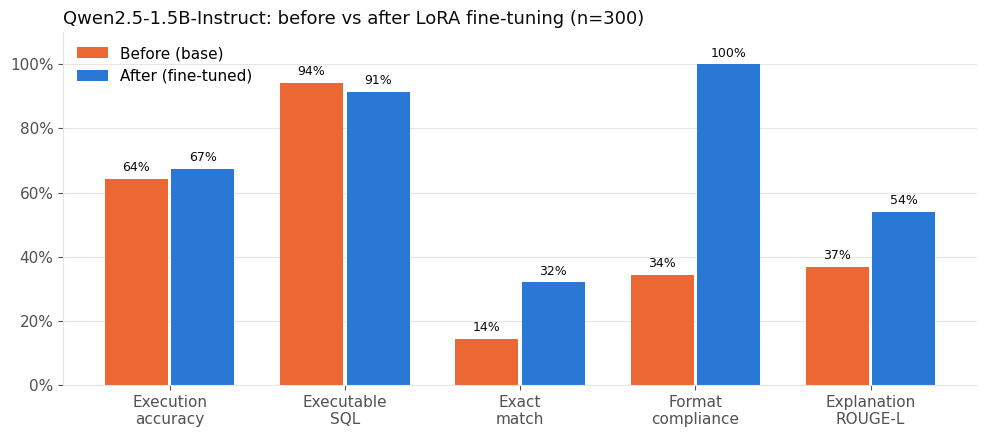

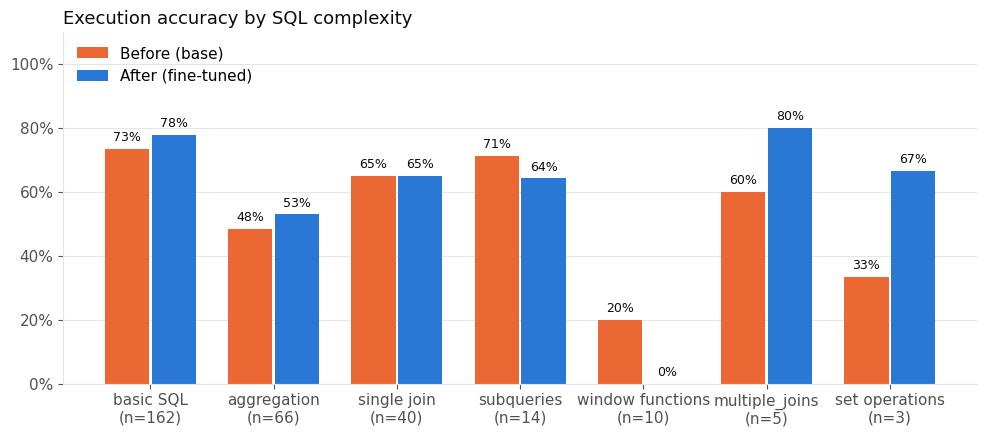

In [12]:
import matplotlib.pyplot as plt

BASE_C, FT_C = "#eb6834", "#2a78d6"            # orange = before, blue = after
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})

def grouped_bars(ax, labels, before, after, title):
    x = range(len(labels)); w = 0.36
    for off, vals, c, name in [(-w/2 - 0.01, before, BASE_C, "Before (base)"), (w/2 + 0.01, after, FT_C, "After (fine-tuned)")]:
        bars = ax.bar([i + off for i in x], vals, w, color=c, label=name, zorder=2)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width()/2, v + 0.015, f"{v:.0%}", ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_xticks(list(x)); ax.set_xticklabels(labels)
    ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.grid(axis="y", color=GRID, zorder=0); ax.set_title(title, loc="left", color=INK, fontsize=13)
    ax.legend(frameon=False, loc="upper left")

cols = ["exec_accuracy", "executable_rate", "exact_match", "format_compliance", "explanation_rougeL"]
names = ["Execution\naccuracy", "Executable\nSQL", "Exact\nmatch", "Format\ncompliance", "Explanation\nROUGE-L"]
fig, ax = plt.subplots(figsize=(10, 4.5))
grouped_bars(ax, names, metrics.loc["base", cols], metrics.loc["finetuned", cols],
             f"{MODEL_ID.split('/')[-1]}: before vs after LoRA fine-tuning (n={len(test_rows)})")
fig.tight_layout(); fig.savefig(os.path.join(RESULTS_DIR, "before_after_metrics.png"), dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
grouped_bars(ax, [f"{c}\n(n={n})" for c, n in by_cx.n.items()], by_cx.base, by_cx.finetuned,
             "Execution accuracy by SQL complexity")
fig.tight_layout(); fig.savefig(os.path.join(RESULTS_DIR, "exec_accuracy_by_complexity.png"), dpi=200); plt.show()

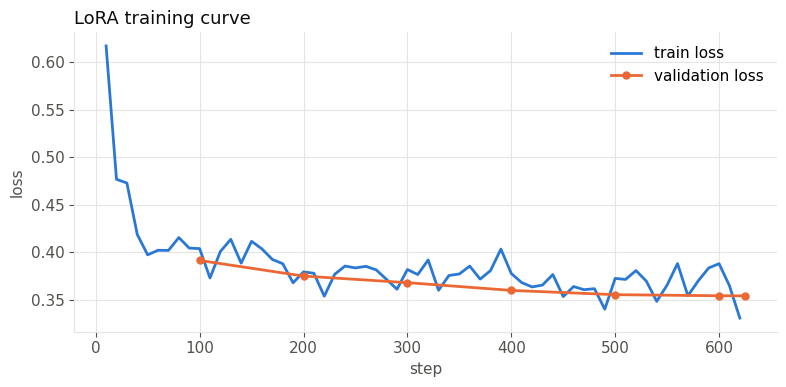

In [13]:
log = pd.DataFrame(trainer.state.log_history)
tr, ev = log.dropna(subset=["loss"]), log.dropna(subset=["eval_loss"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tr.step, tr.loss, color=FT_C, lw=2, label="train loss")
ax.plot(ev.step, ev.eval_loss, color=BASE_C, lw=2, marker="o", ms=5, label="validation loss")
ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.grid(color=GRID)
ax.set_title("LoRA training curve", loc="left", color=INK, fontsize=13); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(RESULTS_DIR, "loss_curve.png"), dpi=200); plt.show()

## 11. Qualitative examples (for the slides)
Questions the base model got wrong and the fine-tuned model got right.

In [14]:
cmp = base_df.merge(ft_df, on=["id", "question", "gold_sql", "sql_complexity"], suffixes=("_base", "_ft"))
fixed = cmp[~cmp.exec_match_base & cmp.exec_match_ft]
print(f"fixed by fine-tuning: {len(fixed)}   broken by fine-tuning: {(cmp.exec_match_base & ~cmp.exec_match_ft).sum()}")

lines = ["# Before vs after examples\n"]
for _, r in fixed.head(5).iterrows():
    lines += [f"## [{r.sql_complexity}] {r.question}\n", f"**Gold SQL:** `{r.gold_sql}`\n",
              "**Before (base):**\n", "~~~\n" + r.raw_output_base.strip() + "\n~~~\n",
              "**After (fine-tuned):**\n", "~~~\n" + r.raw_output_ft.strip() + "\n~~~\n"]
open(os.path.join(RESULTS_DIR, "examples.md"), "w").write("\n".join(lines))
print("\n".join(lines[:8]))

fixed by fine-tuning: 31   broken by fine-tuning: 22
# Before vs after examples

## [aggregation] What is the total retail price of sustainable fabrics by country of origin?

**Gold SQL:** `SELECT country_of_origin, SUM(retail_price) as total_retail_price FROM products GROUP BY country_of_origin;`

**Before (base):**

~~~
To find the total retail price of sustainable fabrics by country of origin, we need to sum up the prices for products where the `country_of_origin` is either "India" or "France". Here's the SQL query to achieve this:

```sql
SELECT SUM(retail_price), country_of_origin
FROM products
WHERE country_of_origin IN ('India', 'France')
GROUP BY country_of_origin;
```

This query works as follows:
- It selects the sum of `retail_price` and the `country_of_origin`.
- It filters the rows where `country_of_origin` is either "India" or "France".
- It groups the results by `country_of_origin` to get the total price per country.
- The `SUM()` function calculates the total retail pri

In [15]:
summary = {"model": MODEL_ID, "train_examples": len(train_rows), "test_examples": len(test_rows),
           "lora": {"r": LORA_R, "alpha": LORA_ALPHA, "dropout": LORA_DROPOUT},
           "train": {"epochs": EPOCHS, "lr": LR, "effective_batch": BATCH * GRAD_ACCUM, "minutes": round(train_minutes, 1),
                     "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else DEVICE},
           "before": base_summary, "after": ft_summary}
json.dump(summary, open(os.path.join(RESULTS_DIR, "summary.json"), "w"), indent=2, default=float)
print("All results written to", RESULTS_DIR)
print("LoRA adapter at", ADAPTER_DIR)

All results written to /content/drive/MyDrive/text-to-sql-finetuning/results
LoRA adapter at /content/drive/MyDrive/text-to-sql-finetuning/outputs/qwen2.5-1.5b-instruct-text2sql-lora/final_adapter
